In [1]:
from codespace_distance import build_circuit
import stim

In [2]:
c = build_circuit()

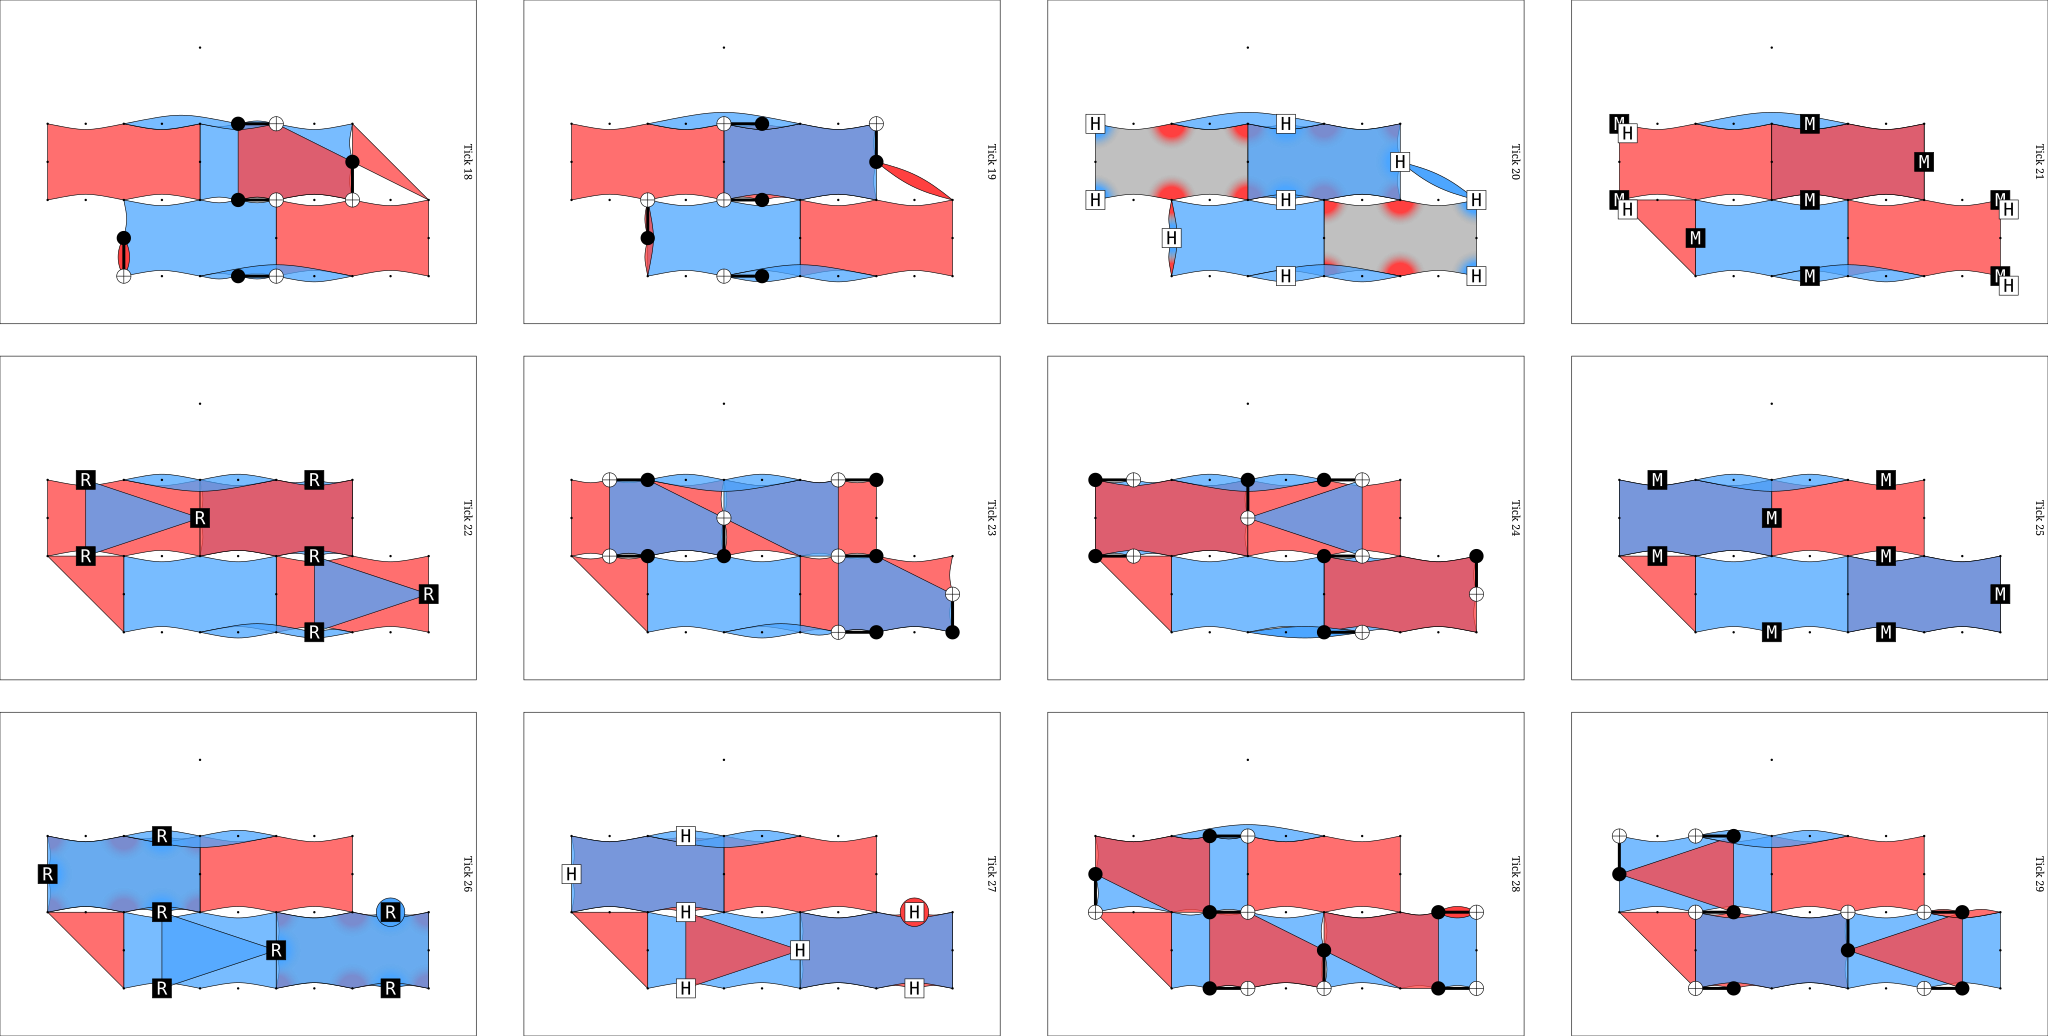

In [6]:
c.without_noise().diagram(
    "timeslice-svg"
    )

diagram = c.without_noise().diagram(
    "detslice-with-ops-svg",
    tick=range(18, 30)
)
display(diagram)  # in Jupyter; otherwise:
with open("error.pdf", "w") as f:
    f.write(str(diagram))

In [7]:
print(c.shortest_graphlike_error())

[stim.ExplainedError(dem_error_terms=(stim.DemTargetWithCoords(dem_target=stim.DemTarget('D14'), coords=[2.25, 0, 35]),), circuit_error_locations=(stim.CircuitErrorLocation(tick_offset=23, flipped_pauli_product=(stim.GateTargetWithCoords(stim.target_x(2), [1, 0]),stim.GateTargetWithCoords(stim.target_x(18), [0.5, 0]),), flipped_measurement=stim.FlippedMeasurement(
    record_index=None,
    observable=(),
), instruction_targets=stim.CircuitTargetsInsideInstruction(gate='DEPOLARIZE2', args=[0.001], target_range_start=0, target_range_end=2, targets_in_range=(stim.GateTargetWithCoords(2, [1, 0]),stim.GateTargetWithCoords(18, [0.5, 0]),)), stack_frames=(stim.CircuitErrorLocationStackFrame(
    instruction_offset=97,
    iteration_index=0,
    instruction_repetitions_arg=0,
),)),stim.CircuitErrorLocation(tick_offset=23, flipped_pauli_product=(stim.GateTargetWithCoords(stim.target_y(2), [1, 0]),stim.GateTargetWithCoords(stim.target_y(18), [0.5, 0]),), flipped_measurement=stim.FlippedMeasurem

In [5]:
circuit = c

# 1. Which noise sources matter? Drop noise from one gate type at a time.
def distance_with(circuit):
    try:
        return len(circuit.shortest_graphlike_error())
    except ValueError:
        return None  # no logical error possible

print("full noise:", distance_with(circuit))

# 2. Compare against a data-only noise model (should give 3 if the code is fine)
from_data_only = stim.Circuit()
for inst in circuit.flattened():
    if inst.name in ("DEPOLARIZE1", "DEPOLARIZE2", "X_ERROR", "Z_ERROR"):
        continue
    from_data_only.append(inst)
# then re-add only DEPOLARIZE1 on data qubits after each round, or use
# stim.Circuit.generated(...) with before_round_data_depolarization only.

# 3. Look at every minimum-weight logical error, not just one
errs = circuit.search_for_undetectable_logical_errors(
    dont_explore_detection_event_sets_with_size_above=4,
    dont_explore_edges_with_degree_above=9999,
    dont_explore_edges_increasing_symptom_degree=False,
    canonicalize_circuit_errors=True,
)
print(len(errs))

# 4. See the geometry: draw the faults on the circuit
circuit.with_inlined_feedback().diagram("detslice-with-ops-svg", tick=range(20, 25))

# 5. Overlay the actual fault on the circuit as a diagram
circuit.diagram("timeline-3d-html")  # inspect where qubit 2 / 4 / 22 sit

full noise: 2
2


<!DOCTYPE html>
<html>
<head>
  <meta charset="UTF-8" />
  <script type="importmap">
    {
      "imports": {
        "three": "https://unpkg.com/three@0.138.0/build/three.module.js",
        "three-orbitcontrols": "https://unpkg.com/three@0.138.0/examples/jsm/controls/OrbitControls.js",
        "three-gltf-loader": "https://unpkg.com/three@0.138.0/examples/jsm/loaders/GLTFLoader.js"
      }
    }
  </script>
</head>
<body>
  <a download="model.gltf" id="stim-3d-viewer-download-link" href="data:text/plain;base64,eyJhY2Nlc3NvcnMiOlt7ImJ1ZmZlclZpZXciOjAsImJ5dGVPZmZzZXQiOjAsImNvbXBvbmVudFR5cGUiOjUxMjYsImNvdW50IjoxMiwibWF4IjpbMCwwLjUsMC41XSwibWluIjpbMCwtMC41LC0wLjVdLCJuYW1lIjoiY3ViZSIsInR5cGUiOiJWRUMzIn0seyJidWZmZXJWaWV3IjoxLCJieXRlT2Zmc2V0IjowLCJjb21wb25lbnRUeXBlIjo1MTI2LCJjb3VudCI6MTIsIm1heCI6WzAuMzc1LDAuNTYyNV0sIm1pbiI6WzAuMzEyNSwwLjVdLCJuYW1lIjoidGV4X2Nvb3Jkc19nYXRlX1IiLCJ0eXBlIjoiVkVDMiJ9LHsiYnVmZmVyVmlldyI6MiwiYnl0ZU9mZnNldCI6MCwiY29tcG9uZW50VHlwZSI6NTEyNiwiY291bnQiOjEyLCJtYXgiOlswLjM3NSwwLjQzNzVdLCJtaW4iOlswLjMxMjUsMC4zNzVdLCJuYW1lIjoidGV4X2Nvb3Jkc19nYXRlX1JYIiwidHlwZSI6IlZFQzIifSx7ImJ1ZmZlclZpZXciOjMsImJ5dGVPZmZzZXQiOjAsImNvbXBvbmVudFR5cGUiOjUxMjYsImNvdW50IjoxMiwibWF4IjpbMC4xMjUsMC41XSwibWluIjpbMC4wNjI1LDAuNDM3NV0sIm5hbWUiOiJ0ZXhfY29vcmRzX2dhdGVfSCIsInR5cGUiOiJWRUMyIn0seyJidWZmZXJWaWV3Ijo0LCJieXRlT2Zmc2V0IjowLCJjb21wb25lbnRUeXBlIjo1MTI2LCJjb3VudCI6MTcsIm1heCI6WzAsMC40MDAwMDAwMDU5NjA0NjQsMC40MDAwMDAwMDU5NjA0NjRdLCJtaW4iOlswLC0wLjQwMDAwMDAwNTk2MDQ2NCwtMC40MDAwMDAwMDU5NjA0NjRdLCJuYW1lIjoiY2lyY2xlX2xvb3AiLCJ0eXBlIjoiVkVDMyJ9LHsiYnVmZmVyVmlldyI6NSwiYnl0ZU9mZnNldCI6MCwiY29tcG9uZW50VHlwZSI6NTEyNiwiY291bnQiOjE3LCJtYXgiOlswLDAuNDAwMDAwMDA1OTYwNDY0LDAuNDAwMDAwMDA1OTYwNDY0XSwibWluIjpbMCwtMC40MDAwMDAwMDU5NjA0NjQsLTAuNDAwMDAwMDA1OTYwNDY0XSwibmFtZSI6ImNpcmNsZV9sb29wIiwidHlwZSI6IlZFQzMifSx7ImJ1ZmZlclZpZXciOjYsImJ5dGVPZmZzZXQiOjAsImNvbXBvbmVudFR5cGUiOjUxMjYsImNvdW50Ijo0LCJtYXgiOlswLDAuNDAwMDAwMDA1OTYwNDY0LDAuNDAwMDAwMDA1OTYwNDY0XSwibWluIjpbMCwtMC40MDAwMDAwMDU5NjA0NjQsLTAuNDAwMDAwMDA1OTYwNDY0XSwibmFtZSI6ImNvbnRyb2xfeF9saW5lX2Nyb3NzIiwidHlwZSI6IlZFQzMifSx7ImJ1ZmZlclZpZXciOjcsImJ5dGVPZmZzZXQiOjAsImNvbXBvbmVudFR5cGUiOjUxMjYsImNvdW50IjoxMiwibWF4IjpbMC4zMTI1LDAuNTYyNV0sIm1pbiI6WzAuMjUsMC41XSwibmFtZSI6InRleF9jb29yZHNfZ2F0ZV9NIiwidHlwZSI6IlZFQzIifSx7ImJ1ZmZlclZpZXciOjgsImJ5dGVPZmZzZXQiOjAsImNvbXBvbmVudFR5cGUiOjUxMjYsImNvdW50IjoxMiwibWF4IjpbMC4yNSwwLjYyNV0sIm1pbiI6WzAuMTg3NSwwLjU2MjVdLCJuYW1lIjoidGV4X2Nvb3Jkc19nYXRlX0RFUE9MQVJJWkUxIiwidHlwZSI6IlZFQzIifSx7ImJ1ZmZlclZpZXciOjksImJ5dGVPZmZzZXQiOjAsImNvbXBvbmVudFR5cGUiOjUxMjYsImNvdW50IjoxMiwibWF4IjpbMC4zMTI1LDAuNjI1XSwibWluIjpbMC4yNSwwLjU2MjVdLCJuYW1lIjoidGV4X2Nvb3Jkc19nYXRlX0RFUE9MQVJJWkUyIiwidHlwZSI6IlZFQzIifSx7ImJ1ZmZlclZpZXciOjEwLCJieXRlT2Zmc2V0IjowLCJjb21wb25lbnRUeXBlIjo1MTI2LCJjb3VudCI6MTIsIm1heCI6WzAuNSwwLjQzNzVdLCJtaW4iOlswLjQzNzUsMC4zNzVdLCJuYW1lIjoidGV4X2Nvb3Jkc19nYXRlX1hfRVJST1IiLCJ0eXBlIjoiVkVDMiJ9LHsiYnVmZmVyVmlldyI6MTEsImJ5dGVPZmZzZXQiOjAsImNvbXBvbmVudFR5cGUiOjUxMjYsImNvdW50IjoxMiwibWF4IjpbMC42ODc1LDAuNDM3NV0sIm1pbiI6WzAuNjI1LDAuMzc1XSwibmFtZSI6InRleF9jb29yZHNfZ2F0ZV9NUFA6WCIsInR5cGUiOiJWRUMyIn0seyJidWZmZXJWaWV3IjoxMiwiYnl0ZU9mZnNldCI6MCwiY29tcG9uZW50VHlwZSI6NTEyNiwiY291bnQiOjEyLCJtYXgiOlswLjY4NzUsMC41NjI1XSwibWluIjpbMC42MjUsMC41XSwibmFtZSI6InRleF9jb29yZHNfZ2F0ZV9NUFA6WiIsInR5cGUiOiJWRUMyIn0seyJidWZmZXJWaWV3IjoxMywiYnl0ZU9mZnNldCI6MCwiY29tcG9uZW50VHlwZSI6NTEyNiwiY291bnQiOjYwMCwibWF4IjpbMSwtMzIsLTMyXSwibWluIjpbLTkxLC01MiwtNDRdLCJuYW1lIjoiYnVmX3NjYXR0ZXJlZF9saW5lcyIsInR5cGUiOiJWRUMzIn0seyJidWZmZXJWaWV3IjoxNCwiYnl0ZU9mZnNldCI6MCwiY29tcG9uZW50VHlwZSI6NTEyNiwiY291bnQiOjYsIm1heCI6WzAsLTI5LjUsLTM4XSwibWluIjpbLTMsLTMwLjUsLTM4XSwibmFtZSI6ImJ1Zl9yZWRfc2NhdHRlcmVkX2xpbmVzIiwidHlwZSI6IlZFQzMifSx7ImJ1ZmZlclZpZXciOjE1LCJieXRlT2Zmc2V0IjowLCJjb21wb25lbnRUeXBlIjo1MTI2LCJjb3VudCI6NDMyLCJtYXgiOlstMC43NSwtMzEuMjAwMDAwNzYyOTM5NSwtMzEuNV0sIm1pbiI6Wy04NC4yNSwtMzEuNjAwMDAwMzgxNDY5NywtNDQuNV0sIm5hbWUiOiJidWZfYmx1ZV9zY2F0dGVyZWRfbGluZXMiLCJ0eXBlIjoiVkVDMyJ9XSwiYXNzZXQiOnsidmVyc2lvbiI6IjIuMCJ9LCJidWZmZXJWaWV3cyI6W3